# 08 发生率预报：2017–2025 测试分段的两条基线

基线公式、核参数、泄漏规则与上一轮完全相同。训练窗与验证窗不变，因此验证集分数应与上一轮实质相同。测试现含 2017–2025；后期 holdout 仅为 2026 年至抓取终点。不训练 ML。

**协议说明：** 2025 年此前已作为 2025–2026 后期 holdout 评过分并展示给用户，本分段下它不再是未见的后期检查。

## 0 公式（与上一轮相同）

基线 1：各格在 535 个完整训练窗中的经验频率 \(p^{\mathrm{emp}} = n_{+}/535\)；并列 Poisson \(1-e^{-\lambda}\)。

基线 2：\(\tau = 3\times 365.25\) 天，\(\sigma=200\) km，截断 800 km，haversine 至格中心（经度差按日界线卷绕）。\(\alpha\) 只在训练窗上估计。窗 \(T\) 只用发震时刻严格早于 \(T_{\mathrm{start}}\) 的事件。评分时概率裁到 \([10^{-6},1-10^{-6}]\)。

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from rate_forecast_lib import KERNEL_TAU_DAYS, KERNEL_SIGMA_KM, KERNEL_CUTOFF_KM, PROB_FLOOR
from rate_forecast_plots import FIG, plot_longterm_rate_map, plot_calibration

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 160)
ROOT = Path("/workspace/08_rate_forecast/split_2017_2025")
PREV = Path("/workspace/08_rate_forecast")
print("tau", KERNEL_TAU_DAYS, "sigma", KERNEL_SIGMA_KM, "cutoff", KERNEL_CUTOFF_KM, "floor", PROB_FLOOR)

tau 1095.75 sigma 200.0 cutoff 800.0 floor 1e-06


## 1 长期发生率与核尺度（训练期，应与上一轮相同）

,region,eval_set,p_const_train,lambda_const_train,kernel_alpha,n_train_events_region,sum_s_train,n_train_pos,n_train_cw
0,china_rectangle,all_mask_cells,0.004512,0.005782,0.005277,3056,579097.474796,2385,528580
1,china_rectangle,historically_active,0.013633,0.017468,0.005277,3056,579097.474796,2385,174945
2,pacific,all_mask_cells,0.000818,0.001084,0.006539,1526,233365.193319,1152,1408120
3,pacific,historically_active,0.009613,0.012734,0.006539,1526,233365.193319,1152,119840
4,union,all_mask_cells,0.001825,0.002368,0.005506,4553,826843.029954,3509,1922790
5,union,historically_active,0.012191,0.015818,0.005506,4553,826843.029954,3509,287830


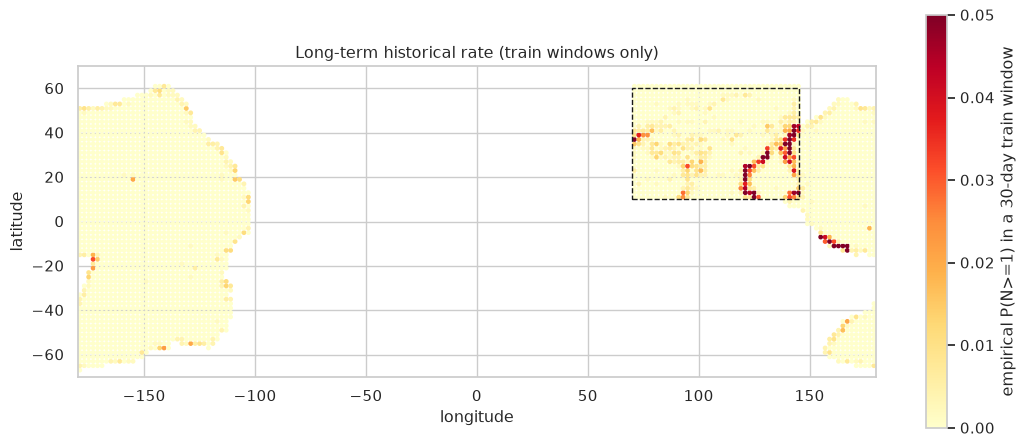

In [2]:
windows = pd.read_csv(ROOT / "windows.csv", parse_dates=["window_start", "window_end"])
cells = pd.read_csv(ROOT / "cells_mask.csv")
rates = pd.read_csv(ROOT / "longterm_cell_rates.csv")
diag = pd.read_csv(ROOT / "train_baseline_diagnostics.csv")
display(diag)
fig = plot_longterm_rate_map(rates, cells, FIG / "baseline_longterm_p_map.png")
plt.show(); plt.close(fig)

## 2 验证 / 新测试 / 2026 holdout 评分

In [3]:
metrics = pd.read_csv(ROOT / "metrics_baselines.csv")
show = [
    "region", "split", "eval_set", "model",
    "n_cells", "n_windows", "n_events", "n_positive", "prevalence",
    "brier", "brier_skill_vs_const", "rel_log_likelihood_vs_const",
    "mean_log_loss", "pr_auc",
]
head = metrics[metrics.model.isin(["longterm_empirical", "recent_kernel", "constant_prevalence"])]
print("=== all mask cells ===")
display(head[head.eval_set == "all_mask_cells"][show].reset_index(drop=True))
print("=== historically active cells ===")
display(head[head.eval_set == "historically_active"][show].reset_index(drop=True))

=== all mask cells ===


,region,split,eval_set,model,n_cells,n_windows,n_events,n_positive,prevalence,brier,brier_skill_vs_const,rel_log_likelihood_vs_const,mean_log_loss,pr_auc
0,china_rectangle,val,all_mask_cells,longterm_empirical,988,97,725,427,0.004456,0.004186,0.056182,745.993023,0.020782,0.092428
1,china_rectangle,val,all_mask_cells,recent_kernel,988,97,725,427,0.004456,0.004474,-0.008667,590.579515,0.022404,0.106104
2,china_rectangle,val,all_mask_cells,constant_prevalence,988,97,725,427,0.004456,0.004436,0.000000,0.000000,0.028566,0.004456
3,china_rectangle,test,all_mask_cells,longterm_empirical,988,108,491,400,0.003749,0.003586,0.039934,611.316815,0.019023,0.067107
4,china_rectangle,test,all_mask_cells,recent_kernel,988,108,491,400,0.003749,0.003676,0.015944,565.266417,0.019454,0.039109
5,china_rectangle,test,all_mask_cells,constant_prevalence,988,108,491,400,0.003749,0.003735,0.000000,0.000000,0.024752,0.003749
6,china_rectangle,holdout,all_mask_cells,longterm_empirical,988,10,56,49,0.004960,0.004644,0.059048,65.173116,0.024690,0.110129
7,china_rectangle,holdout,all_mask_cells,recent_kernel,988,10,56,49,0.004960,0.004702,0.047301,77.950837,0.023396,0.130211
8,china_rectangle,holdout,all_mask_cells,constant_prevalence,988,10,56,49,0.004960,0.004935,0.000000,0.000000,0.031286,0.004960
9,pacific,val,all_mask_cells,longterm_empirical,2632,97,435,270,0.001058,0.000993,0.060128,690.566567,0.005630,0.087584


=== historically active cells ===


,region,split,eval_set,model,n_cells,n_windows,n_events,n_positive,prevalence,brier,brier_skill_vs_const,rel_log_likelihood_vs_const,mean_log_loss,pr_auc
0,china_rectangle,val,historically_active,longterm_empirical,327,97,698,413,0.013021,0.012208,0.050092,405.454985,0.056692,0.095410
1,china_rectangle,val,historically_active,recent_kernel,327,97,698,413,0.013021,0.012914,-0.004842,259.998428,0.061278,0.112777
2,china_rectangle,val,historically_active,constant_prevalence,327,97,698,413,0.013021,0.012851,0.000000,0.000000,0.069475,0.013021
3,china_rectangle,test,historically_active,longterm_empirical,327,108,472,382,0.010817,0.010325,0.035705,339.251293,0.050432,0.070092
4,china_rectangle,test,historically_active,recent_kernel,327,108,472,382,0.010817,0.010586,0.011357,230.996199,0.053498,0.040619
5,china_rectangle,test,historically_active,constant_prevalence,327,108,472,382,0.010817,0.010708,0.000000,0.000000,0.060039,0.010817
6,china_rectangle,holdout,historically_active,longterm_empirical,327,10,53,46,0.014067,0.013113,0.054542,39.355987,0.061921,0.116988
7,china_rectangle,holdout,historically_active,recent_kernel,327,10,53,46,0.014067,0.013264,0.043660,37.056229,0.062624,0.139401
8,china_rectangle,holdout,historically_active,constant_prevalence,327,10,53,46,0.014067,0.013870,0.000000,0.000000,0.073956,0.014067
9,pacific,val,historically_active,longterm_empirical,224,97,393,249,0.011460,0.010701,0.055681,216.888359,0.052794,0.094881


## 3 与上一轮（测试 2017–2024，holdout 2025–2026）对照

旧数字只从父目录快照读取，不改写那些文件。验证分数应基本不变。

In [4]:
key = pd.read_csv(ROOT / "comparison_key_counts_and_scores.csv")
cols = [
    "region", "panel", "old_label", "new_label",
    "old_n_windows", "new_n_windows", "old_events", "new_events",
    "old_pos_all", "new_pos_all", "old_prev_all", "new_prev_all",
    "old_all_emp_brier", "new_all_emp_brier", "old_all_emp_relLL", "new_all_emp_relLL", "old_all_emp_prauc", "new_all_emp_prauc",
    "old_all_kernel_brier", "new_all_kernel_brier", "old_all_kernel_relLL", "new_all_kernel_relLL", "old_all_kernel_prauc", "new_all_kernel_prauc",
]
display(key[cols])

# val identity check
oldm = pd.read_csv(PREV / "metrics_baselines.csv")
newm = metrics
max_abs = 0.0
for region in ["union", "china_rectangle", "pacific"]:
    for evs in ["all_mask_cells", "historically_active"]:
        for model in ["longterm_empirical", "recent_kernel", "constant_prevalence"]:
            o = oldm[(oldm.region==region)&(oldm.eval_set==evs)&(oldm.split=="val")&(oldm.model==model)].iloc[0]
            n = newm[(newm.region==region)&(newm.eval_set==evs)&(newm.split=="val")&(newm.model==model)].iloc[0]
            max_abs = max(max_abs, abs(o.brier-n.brier), abs(o.rel_log_likelihood_vs_const-n.rel_log_likelihood_vs_const), abs(o.pr_auc-n.pr_auc))
print("max abs val-score difference vs previous snapshot:", max_abs)
print("Protocol: 2025 is now inside test and is no longer an unseen later holdout.")

,region,panel,old_label,new_label,old_n_windows,new_n_windows,old_events,new_events,old_pos_all,new_pos_all,old_prev_all,new_prev_all,old_all_emp_brier,new_all_emp_brier,old_all_emp_relLL,new_all_emp_relLL,old_all_emp_prauc,new_all_emp_prauc,old_all_kernel_brier,new_all_kernel_brier,old_all_kernel_relLL,new_all_kernel_relLL,old_all_kernel_prauc,new_all_kernel_prauc
0,union,test,old_test_2017_2024,new_test_2017_2025,96,108,633,732,544,620,0.001577,0.001597,0.001518,0.001536,1081.891655,1263.910442,0.061523,0.062445,0.001552,0.001569,1053.583583,1215.270285,0.035466,0.036181
1,union,holdout,old_holdout_2025_2026,new_holdout_2026,22,10,178,74,146,67,0.001847,0.001864,0.001753,0.001772,328.634177,137.858782,0.075606,0.077076,0.001779,0.001785,310.186892,142.025731,0.082292,0.103837
2,china_rectangle,test,old_test_2017_2024,new_test_2017_2025,96,108,430,491,357,400,0.003764,0.003749,0.003606,0.003586,523.286459,611.316815,0.065883,0.067107,0.003695,0.003676,498.114352,565.266417,0.038472,0.039109
3,china_rectangle,holdout,old_holdout_2025_2026,new_holdout_2026,22,10,120,56,93,49,0.004279,0.004960,0.003998,0.004644,162.704328,65.173116,0.103280,0.110129,0.004090,0.004702,151.098369,77.950837,0.108764,0.130211
4,pacific,test,old_test_2017_2024,new_test_2017_2025,96,108,218,256,199,232,0.000788,0.000816,0.000767,0.000793,364.610405,446.064817,0.050309,0.050911,0.000780,0.000806,389.059402,473.164586,0.029228,0.030433
5,pacific,holdout,old_holdout_2025_2026,new_holdout_2026,22,10,59,19,54,19,0.000933,0.000722,0.000910,0.000714,117.409246,36.000348,0.048001,0.048361,0.000910,0.000710,120.652142,35.055583,0.043944,0.034722
6,union,val,old_val_2009_2016,new_val_2009_2016,97,97,1130,1130,683,683,0.001959,0.001959,0.001838,0.001838,1623.678542,1623.678542,0.093791,0.093791,0.001956,0.001956,1346.774684,1346.774684,0.086311,0.086311
7,china_rectangle,val,old_val_2009_2016,new_val_2009_2016,97,97,725,725,427,427,0.004456,0.004456,0.004186,0.004186,745.993023,745.993023,0.092428,0.092428,0.004474,0.004474,590.579515,590.579515,0.106104,0.106104
8,pacific,val,old_val_2009_2016,new_val_2009_2016,97,97,435,435,270,270,0.001058,0.001058,0.000993,0.000993,690.566567,690.566567,0.087584,0.087584,0.001037,0.001037,600.355098,600.355098,0.061984,0.061984


max abs val-score difference vs previous snapshot: 0.0
Protocol: 2025 is now inside test and is no longer an unseen later holdout.


## 4 校准图

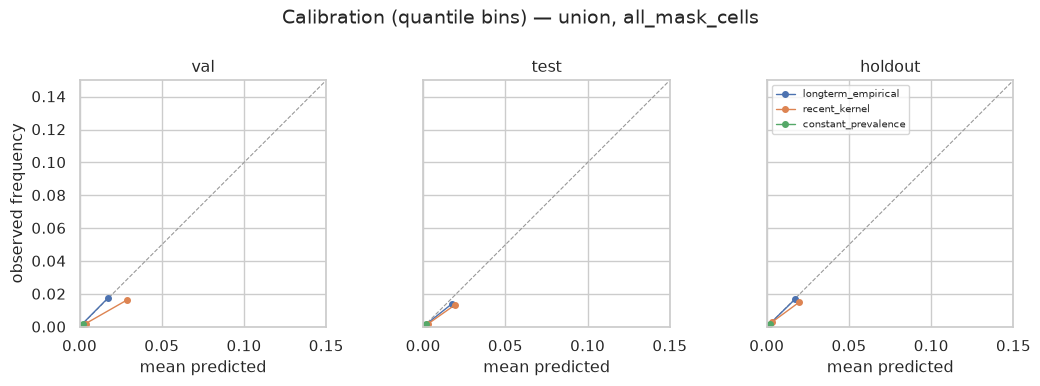

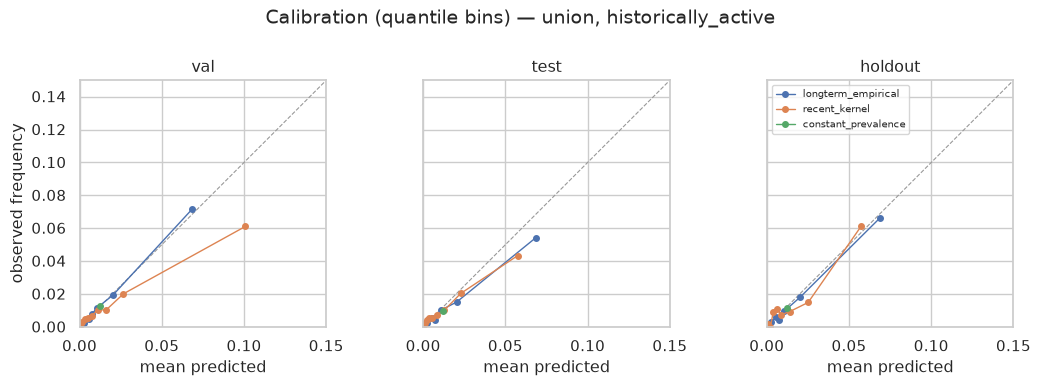

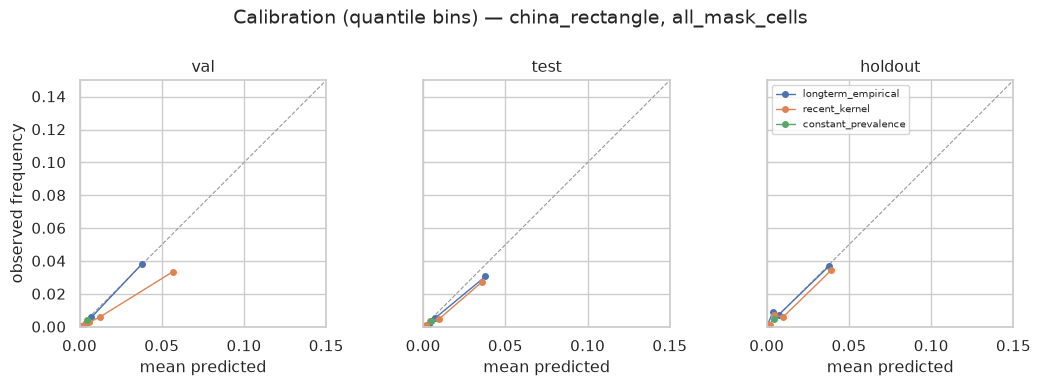

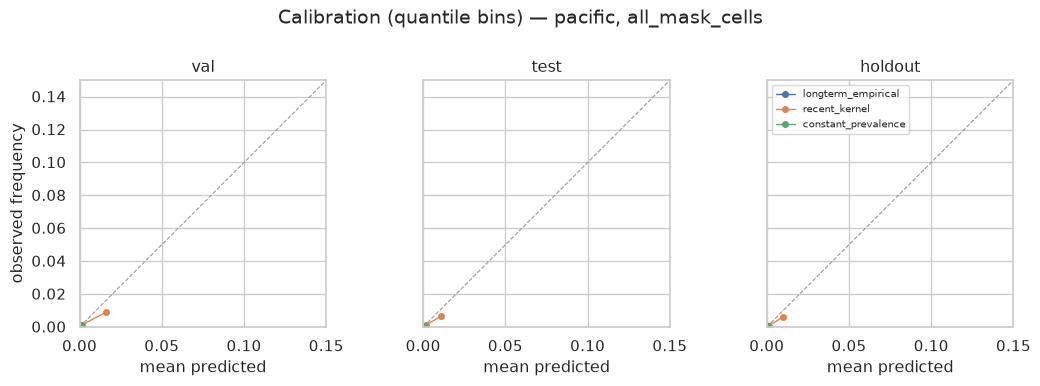

In [5]:
cal = pd.read_csv(ROOT / "calibration_bins.csv")
for region, evs, fname in [
    ("union", "all_mask_cells", "calibration_union_all.png"),
    ("union", "historically_active", "calibration_union_active.png"),
    ("china_rectangle", "all_mask_cells", "calibration_china_all.png"),
    ("pacific", "all_mask_cells", "calibration_pacific_all.png"),
]:
    fig = plot_calibration(cal, region, evs, FIG / fname)
    plt.show(); plt.close(fig)

产出均在 `/workspace/08_rate_forecast/split_2017_2025/`：`metrics_baselines.csv`、`comparison_key_counts_and_scores.csv`、`calibration_bins.csv`、`methodology.json` 与 `figures/`。父目录上一轮快照未改动。